# Proyecto 2 · Movimiento, densidad temporal y conclusiones
## Dinámica entre frames y contexto de los pases

**CC3084 – Ciencia de Datos · Semestre II 2026**


Un pase es un patrón **espacio-temporal**: la señal clave es el **movimiento** entre
frames. Aquí se estudia la variable `motion` (diferencia media entre frames sucesivos)
y se cruza con la densidad temporal de los pases anotados en `train.csv` (contexto).


In [1]:
import pandas as pd, numpy as np, ast
import matplotlib.pyplot as plt
df = pd.read_csv('../data/frame_features.csv')
train = pd.read_csv('../data/train.csv')
mv = df[df.motion > 0]
print('Movimiento medio:', round(mv.motion.mean(),2), '| desv:', round(mv.motion.std(),2))


Movimiento medio: 24.12 | desv: 7.04


## 1. Distribución del movimiento entre frames


/var/folders/75/qq7qyc9j5kd658zsm1nr96mc0000gn/T/ipykernel_96880/131499887.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(mv.motion, vert=False, showfliers=True)


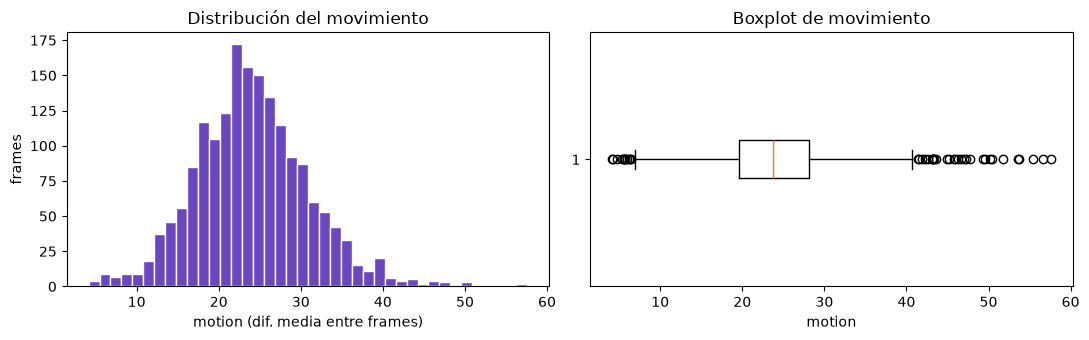

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(mv.motion, bins=40, color='#6b46c1', edgecolor='white')
ax[0].set(xlabel='motion (dif. media entre frames)', ylabel='frames', title='Distribución del movimiento')
ax[1].boxplot(mv.motion, vert=False, showfliers=True)
ax[1].set(title='Boxplot de movimiento', xlabel='motion')
fig.tight_layout(); fig.savefig('../outputs/15_motion_dist.png'); plt.show()


## 2. ¿Qué explica el movimiento? (correlaciones y dispersión)


motion          1.00
edge_density    0.30
green_ratio    -0.31
player_count    0.08
contrast        0.39
Name: motion, dtype: float64


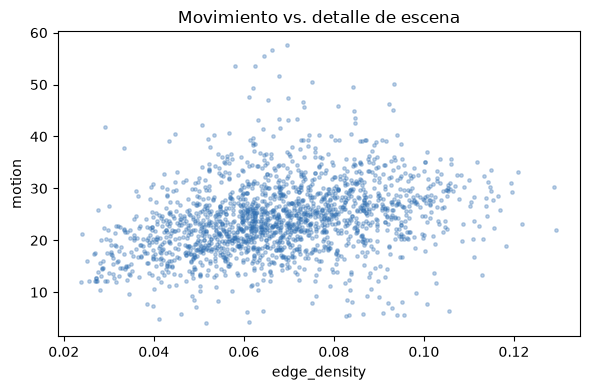

In [3]:
cols = ['motion','edge_density','green_ratio','player_count','contrast']
print(mv[cols].corr().round(2)['motion'])
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(mv.edge_density, mv.motion, s=6, alpha=0.3, color='#2b6cb0')
ax.set(xlabel='edge_density', ylabel='motion', title='Movimiento vs. detalle de escena')
fig.tight_layout(); fig.savefig('../outputs/16_motion_scatter.png'); plt.show()


El movimiento correlaciona con el detalle de la escena y con los cambios de cámara.
En un detector de pases, los picos de `motion` marcan candidatos de acción a revisar.


## 3. Contexto: densidad temporal de pases (`train.csv`)


Pases totales: 3468
Segundos entre pases: media 9.9 | mediana 4.1


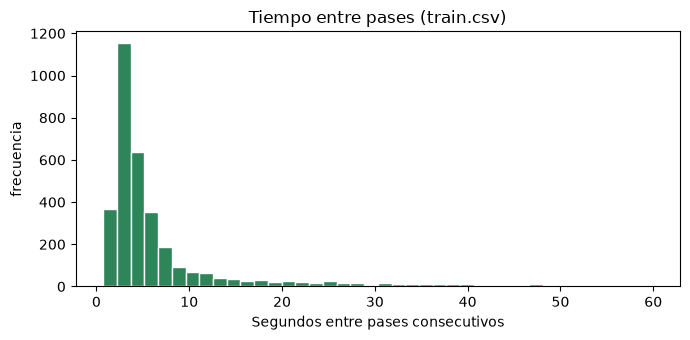

In [4]:
def toks(v):
    try: return ast.literal_eval(v) if isinstance(v,str) and v.strip() else []
    except: return []
plays = train[train.event=='play'].copy()
plays['is_pass'] = plays.event_attributes.apply(lambda x: 'pass' in toks(x))
passes = plays[plays.is_pass]
gap = passes.sort_values(['video_id','time']).groupby('video_id').time.diff().dropna()
print('Pases totales:', len(passes))
print('Segundos entre pases: media', round(gap.mean(),1), '| mediana', round(gap.median(),1))
fig, ax = plt.subplots(figsize=(7,3.5))
ax.hist(gap[gap<60], bins=40, color='#2f855a', edgecolor='white')
ax.set(xlabel='Segundos entre pases consecutivos', ylabel='frecuencia', title='Tiempo entre pases (train.csv)')
fig.tight_layout(); fig.savefig('../outputs/17_pass_gap.png'); plt.show()


Los pases ocurren **cada pocos segundos** en fase de juego abierto: un detector debe
operar con buena resolución temporal (los 25 fps de los clips lo permiten).


---
# 4. Hallazgos y conclusiones

**Hallazgos del análisis exploratorio**

1. **Datos homogéneos y de calidad.** 200 clips, 1080p a 25 fps, 30 s cada uno; sin
   corrupción ni faltantes. Formato uniforme entre los 20 partidos.
2. **La cancha es fácil de aislar.** `green_ratio` es alto y estable, y separa las tomas
   de juego abierto (útiles) de repeticiones y primeros planos (`green_ratio` bajo,
   `edge_density` alto).
3. **Los jugadores son detectables.** YOLOv8 preentrenado los cuenta de forma coherente,
   muy por encima del proxy clásico por blobs (que sobre-estimaba por ruido de gradas).
4. **Los equipos son separables por color.** El matiz de camiseta se agrupa en dos
   equipos con k-means → base para contar pases *por equipo*.
5. **El movimiento es la señal temporal clave** y marca los momentos de acción.
6. **Contexto de pases (train.csv):** 3,468 pases, dominados por juego abierto, que
   ocurren cada pocos segundos y a lo largo de todo el partido; distribución de tipos
   **desbalanceada** (openplay >> freekick, cross, corner).

**Retos identificados**

- El **balón** es pequeño y rápido: será lo más difícil de detectar.
- **Marca de agua y caja del marcador** superpuestas en todos los clips.
- **Desbalance** de tipos de pase y **ausencia de etiquetas** en los clips descargables.

**Conclusiones y siguientes pasos**

- El dataset es **viable** para un sistema de detección de pases basado en visión.
- Pipeline propuesto: muestrear frames → detectar jugadores/balón (YOLO) → asignar
  equipo por color → seguir el balón (tracking) → clasificar la acción con un modelo
  temporal, usando los picos de `motion` como candidatos.
- Para **entrenar y evaluar** se necesitan los videos anotados (los `video_id` de
  `train.csv`) o etiquetar manualmente una muestra de los clips.
